> **Data note:** this notebook was run on the TripleTen platform, which provides the datasets at `/datasets/`. To re-run it locally, download the TomTom Traffic Index and OECD city data and update the paths in the loading cell.

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

### 1.1 Carga de datos y vista rápida

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
traffic.head()

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


In [ ]:
traffic.info()
print()
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

## 🧩Paso 2: Explorar, limpiar y preparar los datos

### 2.1 Explorar la estructura y tipos de datos

In [ ]:
print(eco['Year'].unique())
print(traffic['UpdateTimeUTC'].min(), '->', traffic['UpdateTimeUTC'].max())
print('ciudades traffic:', traffic['City'].nunique())
print('ciudades eco:', eco['City'].nunique())

[2023 2024]
2024-10-01 07:00:59.231 -> 2025-01-13 04:31:30.001
ciudades traffic: 384
ciudades eco: 15


In [ ]:
traffic.info()
traffic.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232



En la estructura del DF traffic, se observa que:

Las columnas UpdateTimeUTC y UpdateTimeUTCWeekAgo son de tipo object (texto) cuando deberían ser datetime64. Hay que convertirlas con pd.to_datetime() para poder extraer el año.
Las 8 columnas de métricas de tráfico ya son float64, correcto.
Country guarda el código ISO-3 del país (ARE), mientras que en eco aparece el nombre completo. No sirve como clave de unión sin normalizar.
No hay datos ausentes: las 12 columnas tienen 1.004.464 valores no nulos sobre 1.004.464 filas.
La granularidad es muy fina: hay múltiples actualizaciones por ciudad y día, 384 ciudades en total. Habrá que agregar por ciudad antes de unir con eco.

In [ ]:
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"



En la estructura del DF eco, se observa que:

Las columnas City GDP/capita, Unemployment %, PM2.5 (µg/m³) y Population (M) son de tipo object cuando deberían ser float64. Vienen en formato europeo (punto como separador de miles y coma decimal, por ejemplo 15.782,00) y Unemployment % incluye además el símbolo %. Hay que limpiar esos caracteres antes de convertirlas.
Year es int64, correcto.
Los nombres de columna contienen espacios, barras, paréntesis y símbolos especiales, lo que dificulta el acceso y la escritura del código. Conviene estandarizarlos a snake_case.
No hay datos ausentes: las 7 columnas tienen 30 valores no nulos sobre 30 filas.
Son 30 filas con 15 ciudades únicas y dos años (2023 y 2024), es decir, una fila por ciudad y año. La clave de este DF es City + Year, no City sola.

### 2.2 Renombrar columnas

In [ ]:
traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_km',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10km_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_historic_per_10km_mins',
    'MinsDelay': 'mins_delay'
})

traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_km', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10km_mins', 'travel_time_historic_per_10km_mins',
       'mins_delay'],
      dtype='object')

In [ ]:
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25',
    'Population (M)': 'population_m'
})

eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')

### 2.3 Corregir formatos numéricos y de fecha

In [ ]:
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='coerce')

traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                              Non-Null Count    Dtype         
---  ------                              --------------    -----         
 0   country                             1004464 non-null  object        
 1   city                                1004464 non-null  object        
 2   update_time_utc                     1004464 non-null  datetime64[ns]
 3   jams_delay                          1004464 non-null  float64       
 4   traffic_index_live                  1004464 non-null  float64       
 5   jams_length_km                      1004464 non-null  float64       
 6   jams_count                          1004464 non-null  float64       
 7   traffic_index_week_ago              1004464 non-null  float64       
 8   update_time_utc_week_ago            1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10km_mins      1004464 non-null  float64       

In [ ]:
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '', regex=False).str.replace(',', '.', regex=False).astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.', regex=False).astype(float)
eco['pm25'] = eco['pm25'].astype(str).str.replace(',', '.', regex=False).astype(float)

eco['population'] = eco['population_m'] * 1000000

eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     float64
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(5), int64(1), object(2)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0


## 🧩Paso 3: Extraer año y filtrar

### 3.1 Extraer columna año y filtrar 2024

In [ ]:
traffic['year'] = traffic['update_time_utc'].dt.year

traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_km,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10km_mins,travel_time_historic_per_10km_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

display(traffic_2024.head())
display(eco_2024.head())

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_km,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10km_mins,travel_time_historic_per_10km_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,12.8,4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,15.2,3.9,3900000.0


## 🧩Paso 4: Analizar y resumir datos de movilidad

### 4.1 Calcular promedios de tráfico por ciudad

In [ ]:
print(len(traffic), '->', len(traffic_2024))
print(len(eco), '->', len(eco_2024))

1004464 -> 886779
30 -> 15


In [ ]:
traffic_city_year_2024 = traffic_2024.groupby(['city', 'country', 'year'])[[
    'jams_delay',
    'traffic_index_live',
    'jams_length_km',
    'jams_count',
    'mins_delay',
    'travel_time_live_per_10km_mins',
    'travel_time_historic_per_10km_mins'
]].mean().reset_index()

traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay,travel_time_live_per_10km_mins,travel_time_historic_per_10km_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [ ]:
print(len(traffic_2024), '->', len(traffic_city_year_2024))

886779 -> 387


In [ ]:
print(eco['city_gdp_capita'].head(3).tolist())

[15782.0, 14475.0, 13142.0]


In [ ]:
set(eco_2024['city']) - set(traffic_city_year_2024['city'])

set()

In [ ]:
merged = pd.merge(
    eco_2024,
    traffic_city_year_2024,
    on=['city', 'year'],
    how='inner'
)

print(len(merged))
merged.head()

15


,year,city,country_x,city_gdp_capita,unemployment_pct,pm25,population_m,population,country_y,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay,travel_time_live_per_10km_mins,travel_time_historic_per_10km_mins
0,2024,buenos-aires,Argentina,18117.0,7.2,14.5,15.4,15400000.0,ARG,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349
1,2024,sao-paulo,Brazil,14703.0,8.5,28.0,22.6,22600000.0,BRA,1729.189270,26.877932,238.419896,431.470460,1.129026,20.801836,19.672810
2,2024,rio-de-janeiro,Brazil,13349.0,9.2,18.4,13.7,13700000.0,BRA,466.064706,25.162963,85.015120,123.891939,0.361302,17.137320,16.776018
3,2024,brasilia,Brazil,16251.0,7.8,12.8,4.8,4800000.0,BRA,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216
4,2024,salvador,Brazil,8899.0,12.4,15.2,3.9,3900000.0,BRA,86.400000,20.928728,13.170442,25.235243,0.115811,16.831620,16.715810


In [ ]:
merged[['city', 'year']].duplicated().sum()
merged.isna().sum()

year                                  0
city                                  0
country_x                             0
city_gdp_capita                       0
unemployment_pct                      0
pm25                                  0
population_m                          0
population                            0
country_y                             0
jams_delay                            0
traffic_index_live                    0
jams_length_km                        0
jams_count                            0
mins_delay                            0
travel_time_live_per_10km_mins        0
travel_time_historic_per_10km_mins    0
dtype: int64

In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay,travel_time_live_per_10km_mins,travel_time_historic_per_10km_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es Ciudad de México (jams_delay = 2.833 min), seguida de Tokio, Nueva York y Londres. Sorprende que el top esté dominado por megalópolis de distintas regiones y no por una zona concreta.

Sin embargo, jams_delay es un total acumulado sobre toda la red monitoreada, por lo que mide sobre todo el tamaño de la ciudad y la extensión de la cobertura de TomTom. Al ordenar por mins_delay (retraso por cada 10 km, normalizado por distancia), el ranking cambia por completo: Manila, Estambul y Bucarest pasan al frente, y Ciudad de México cae al noveno puesto.

La conclusión es que "la ciudad más congestionada" depende de la métrica elegida. Para comparar ciudades de tamaños distintos hay que usar indicadores normalizados (mins_delay, traffic_index_live), no totales absolutos. Manila es el caso más claro: encabeza mins_delay y tiene un traffic_index_live de 66, muy por encima del resto.

## 🧩Paso 5: Unir movilidad y economía

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

In [ ]:
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_km','jams_count','mins_delay',
             'travel_time_live_per_10km_mins','travel_time_historic_per_10km_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

merged = pd.merge(traffic_2024_small, eco_2024_small, on=['city','year'], how='inner')

merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_km,jams_count,mins_delay,travel_time_live_per_10km_mins,travel_time_historic_per_10km_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3700000.0


In [ ]:
print(len(merged))
print(merged[['city','year']].duplicated().sum())
merged.isna().sum()

15
0


city                                  0
country                               0
year                                  0
jams_delay                            0
traffic_index_live                    0
jams_length_km                        0
jams_count                            0
mins_delay                            0
travel_time_live_per_10km_mins        0
travel_time_historic_per_10km_mins    0
city_gdp_capita                       0
unemployment_pct                      0
pm25                                  0
population                            0
dtype: int64

## 🧩Paso 6: Visualización y análisis de relaciones

### 6.1 Visualizar relaciones entre economía y tráfico

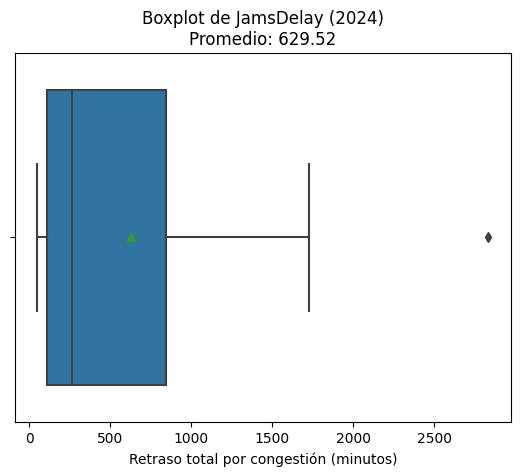

In [ ]:
sns.boxplot(data=merged, x='jams_delay', showmeans=True)
plt.xlabel('Retraso total por congestión (minutos)')

mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()

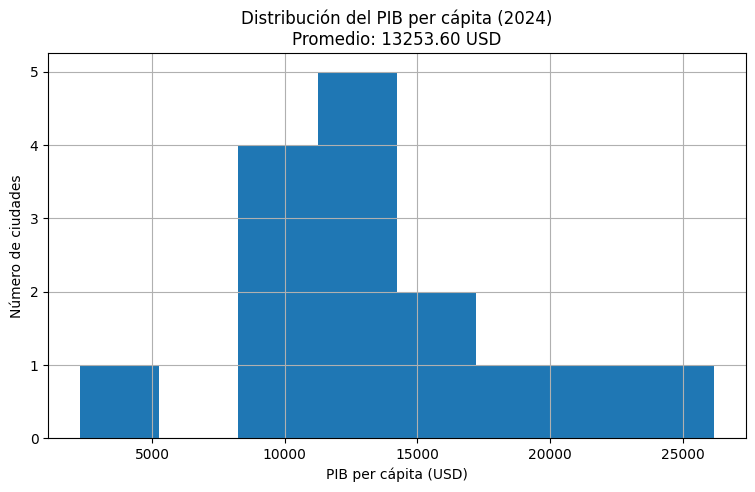

In [ ]:
merged['city_gdp_capita'].hist(bins=8, figsize=(9, 5))
plt.title(f'Distribución del PIB per cápita (2024)\nPromedio: {merged["city_gdp_capita"].mean():.2f} USD')
plt.xlabel('PIB per cápita (USD)')
plt.ylabel('Número de ciudades')
plt.show()

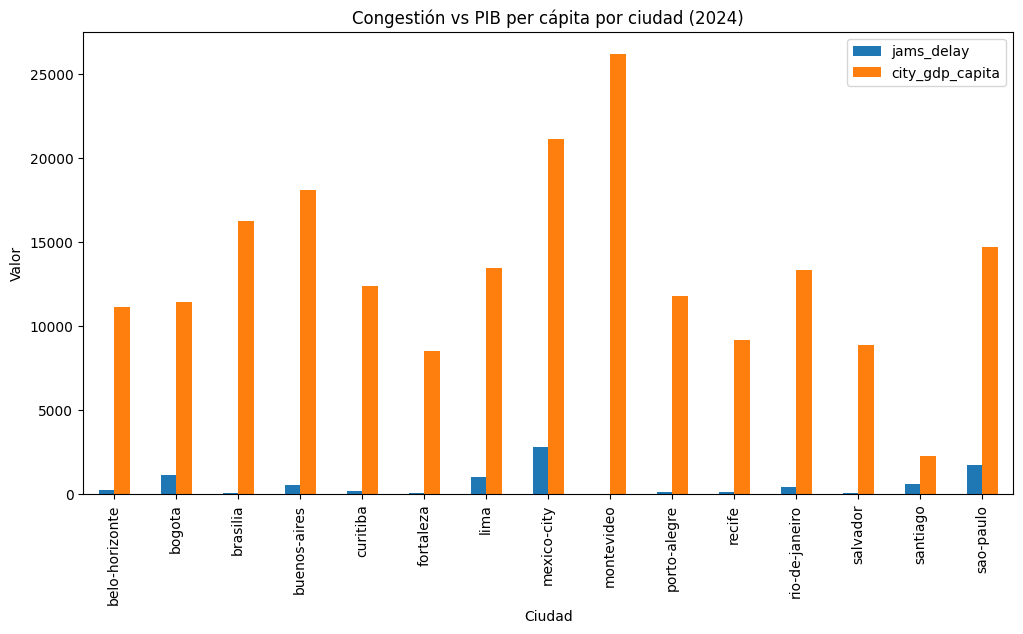

In [ ]:
merged.plot(x='city', kind='bar', y=['jams_delay', 'city_gdp_capita'], figsize=(12, 6))
plt.title('Congestión vs PIB per cápita por ciudad (2024)')
plt.xlabel('Ciudad')
plt.ylabel('Valor')
plt.xticks(rotation=90)
plt.show()

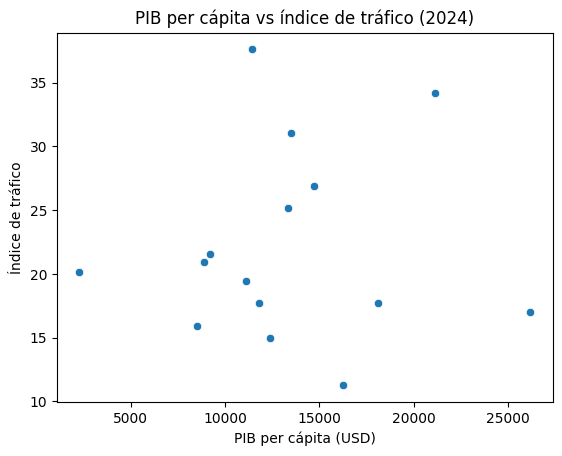

                    city_gdp_capita  traffic_index_live  unemployment_pct  \
city_gdp_capita            1.000000            0.056001         -0.514407   
traffic_index_live         0.056001            1.000000         -0.293692   
unemployment_pct          -0.514407           -0.293692          1.000000   
mins_delay                 0.237215            0.892927         -0.592742   

                    mins_delay  
city_gdp_capita       0.237215  
traffic_index_live    0.892927  
unemployment_pct     -0.592742  
mins_delay            1.000000  


In [ ]:
sns.scatterplot(data=merged, x='city_gdp_capita', y='traffic_index_live')
plt.title('PIB per cápita vs índice de tráfico (2024)')
plt.xlabel('PIB per cápita (USD)')
plt.ylabel('Índice de tráfico')
plt.show()

print(merged[['city_gdp_capita','traffic_index_live','unemployment_pct','mins_delay']].corr())

In [ ]:
print(merged[['city_gdp_capita','unemployment_pct','jams_delay','traffic_index_live','mins_delay','population']].corr()['city_gdp_capita'])

city_gdp_capita       1.000000
unemployment_pct     -0.514407
jams_delay            0.282975
traffic_index_live    0.056001
mins_delay            0.237215
population            0.276688
Name: city_gdp_capita, dtype: float64


In [ ]:
print(merged[['population','jams_delay','traffic_index_live']].corr())

                    population  jams_delay  traffic_index_live
population            1.000000    0.878525            0.647225
jams_delay            0.878525    1.000000            0.765017
traffic_index_live    0.647225    0.765017            1.000000



Al calcular las correlaciones entre el PIB per cápita y las variables de movilidad, los coeficientes son muy bajos: 0,06 con traffic_index_live y 0,28 con jams_delay. No existe relación apreciable: las ciudades con mayor PIB per cápita no presentan más congestión, ni tampoco menos.

Lo que sí aparece es otra relación, mucho más fuerte: la población correlaciona 0,88 con jams_delay y 0,65 con traffic_index_live. El tamaño de la ciudad explica la congestión muchísimo mejor que su nivel de riqueza.

La diferencia entre esos dos coeficientes (0,88 frente a 0,65) tiene sentido: jams_delay es un total acumulado sobre toda la red monitoreada, así que mide en parte el tamaño de la propia ciudad. traffic_index_live, al estar normalizado en una escala 0–100, refleja mejor la intensidad real de la congestión.

Como control de coherencia, PIB per cápita y desempleo correlacionan −0,51, en la dirección esperable.

Limitaciones: la muestra es de solo 15 ciudades latinoamericanas, y los datos de tráfico cubren únicamente octubre–diciembre de 2024, no el año completo. Además, correlación no implica causalidad: aunque población y congestión vayan juntas, eso no dice si el tamaño causa la congestión o si ambos dependen de factores como la inversión en transporte público.

## 🧩Paso 7: Exportar y documentar resultados

### 7.1 Guardar dataset final

In [ ]:
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

In [ ]:
resumen = merged[['city','country','traffic_index_live','mins_delay','city_gdp_capita','unemployment_pct','population']].copy()
resumen = resumen.sort_values('traffic_index_live', ascending=False)
print(resumen.to_string(index=False))

          city country  traffic_index_live  mins_delay  city_gdp_capita  unemployment_pct  population
        bogota     COL           37.614273    1.699628          11442.0              10.0  11300000.0
   mexico-city     MEX           34.218190    1.855542          21111.0               3.2  22100000.0
          lima     PER           31.031277    1.506305          13472.0               6.5  11200000.0
     sao-paulo     BRA           26.877932    1.129026          14703.0               8.5  22600000.0
rio-de-janeiro     BRA           25.162963    0.361302          13349.0               9.2  13700000.0
        recife     BRA           21.555944    0.072539           9189.0              11.2   4100000.0
      salvador     BRA           20.928728    0.115811           8899.0              12.4   3900000.0
      santiago     CHL           20.155352    0.627445           2277.0               7.8   7100000.0
belo-horizonte     BRA           19.428946    0.487228          11124.0           

## Resumen ejecutivo

**Contexto y objetivo.** Este análisis evalúa si existe relación entre la movilidad urbana y la productividad económica en ciudades latinoamericanas, para orientar decisiones de inversión en infraestructura de transporte. Las variables clave son `traffic_index_live` (índice normalizado de congestión, 0–100), `mins_delay` (retraso en minutos por cada 10 km) y `jams_delay` (retraso total acumulado), junto a `city_gdp_capita` (PIB per cápita en USD) y `unemployment_pct`. Las dos primeras son comparables entre ciudades de distinto tamaño; `jams_delay`, al ser un total absoluto, depende de la extensión de la red monitoreada.

**Cobertura de datos.** El dataset final integra **15 ciudades** de **7 países** (Brasil, Colombia, México, Perú, Chile, Argentina y Uruguay) para el año **2024**. Brasil aporta 8 de las 15 ciudades, lo que sesga la muestra hacia ese país. Además, los datos de TomTom abarcan de octubre de 2024 a enero de 2025, por lo que al filtrar 2024 el análisis refleja solo el trimestre octubre–diciembre, no el año completo.

**Metodología.** Se partió de TomTom Traffic Index (1.004.464 registros) y OECD Cities (30 registros). La limpieza incluyó conversión de fechas a datetime, corrección de columnas numéricas que venían como texto en formato europeo (punto de miles, coma decimal, símbolo `%`) y estandarización de nombres a snake_case. Los datos de tráfico se agregaron por ciudad, país y año mediante promedios, pasando de 886.779 registros a 387. La integración se hizo con un INNER JOIN sobre `city` y `year`, verificando previamente que las 15 ciudades económicas existieran en la fuente de tráfico. El resultado tiene 15 filas, sin duplicados de clave ni nulos. La validación visual incluyó boxplot para outliers de congestión e histograma para la distribución del PIB.

**Hallazgos.** El resultado principal es negativo pero informativo: **no existe relación entre PIB per cápita y congestión**. La correlación con `traffic_index_live` es de 0,06 y con `jams_delay` de 0,28. Lo que sí explica la congestión es el **tamaño de la ciudad**: la población correlaciona 0,88 con `jams_delay` y 0,65 con `traffic_index_live`. La diferencia entre ambos coeficientes es coherente, ya que `jams_delay` incorpora el efecto del tamaño de la red. Como control, PIB y desempleo correlacionan −0,51, en la dirección esperable.

Se detectan dos anomalías que requieren revisión. Primera: **Santiago de Chile figura con 2.277 USD de PIB per cápita**, cinco veces menos que Montevideo y menos de la mitad que Salvador. Siendo Chile uno de los países de mayor renta de la región, el valor es implausible y apunta a un error de la fuente. Segunda: `mins_delay` presenta valores negativos en algunas ciudades del dataset completo, lo que indica que se circulaba más rápido que el tiempo histórico de referencia.

**Recomendaciones.** El enunciado pregunta qué ciudad muestra la mayor correlación entre congestión y baja productividad. Cabe precisar que una correlación no puede calcularse para una ciudad individual, ya que requiere múltiples observaciones; lo que sí puede identificarse es qué ciudad combina peor ambos indicadores. Según los datos, **Bogotá** es la candidata prioritaria: encabeza el índice de congestión (37,6), con un PIB per cápita de 11.442 USD por debajo de la mediana de la muestra y un desempleo del 10,0%. Ciudad de México presenta congestión similar (34,2) pero casi el doble de PIB (21.111 USD), y Lima queda tercera en ambos indicadores.

Antes de comprometer inversión se recomienda: (1) verificar el dato de Santiago con la fuente original; (2) ampliar la ventana temporal a doce meses, ya que un trimestre puede estar afectado por estacionalidad; (3) ampliar la muestra más allá de 15 ciudades y equilibrar la representación por país; y (4) incorporar variables de transporte público y densidad urbana, dado que la población explica la congestión mucho mejor que la riqueza y probablemente existen factores intermedios sin medir. Las correlaciones halladas no establecen causalidad.